In [ ]:
import numpy as np
import pandas as pd
import random
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models, backend as K
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    classification_report, confusion_matrix,
    roc_curve, auc
)
import itertools

In [ ]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

In [ ]:
path_normal = r"/content/drive/MyDrive/normal.csv"
path_anomaly = r"/content/drive/MyDrive/anomaly.csv"

df_normal = pd.read_csv(path_normal, header=None).values
df_anomaly = pd.read_csv(path_anomaly, header=None).values


In [ ]:
TRAIN_P = 0.15
VAL_P   = 0.15
TEST_P  = 0.70
def split_few_shot(X):
    n = len(X)
    idx = np.random.permutation(n)

    n_tr  = int(TRAIN_P * n)
    n_val = int(VAL_P * n)

    X_tr  = X[idx[:n_tr]]
    X_val = X[idx[n_tr:n_tr+n_val]]
    X_te  = X[idx[n_tr+n_val:]]

    return X_tr, X_val, X_te
Xn_tr, Xn_val, Xn_te = split_few_shot(df_normal)
Xa_tr, Xa_val, Xa_te = split_few_shot(df_anomaly)

print("Train:", len(Xn_tr), len(Xa_tr))
print("Val  :", len(Xn_val), len(Xa_val))
print("Test :", len(Xn_te), len(Xa_te))


Train: 18 13
Val  : 18 13
Test : 87 62


In [ ]:
def create_balanced_pairs(Xn, Xa, max_pairs=2000):

    pairs, labels = [], []


    similar_pairs = list(itertools.combinations(range(len(Xn)), 2))


    dissimilar_pairs = [(i, j) for i in range(len(Xn)) for j in range(len(Xa))]


    n_per_class = min(len(similar_pairs), len(dissimilar_pairs), max_pairs // 2)


    similar_idx = np.random.choice(len(similar_pairs), n_per_class, replace=False)
    dissimilar_idx = np.random.choice(len(dissimilar_pairs), n_per_class, replace=False)


    for idx in similar_idx:
        i, j = similar_pairs[idx]
        pairs.append([Xn[i], Xn[j]])
        labels.append(1)

    for idx in dissimilar_idx:
        i, j = dissimilar_pairs[idx]
        pairs.append([Xn[i], Xa[j]])
        labels.append(0)


    pairs = np.array(pairs)
    labels = np.array(labels)
    shuffle_idx = np.random.permutation(len(pairs))

    return pairs[shuffle_idx], labels[shuffle_idx]


In [ ]:
pairs_tr, y_tr   = create_balanced_pairs(Xn_tr, Xa_tr, max_pairs=3000)
pairs_val, y_val = create_balanced_pairs(Xn_val, Xa_val, max_pairs=2000)
pairs_te, y_te   = create_balanced_pairs(Xn_te, Xa_te, max_pairs=3000)

print(f"\nTrain pairs: {len(pairs_tr)} (Similar: {y_tr.sum()}, Dissimilar: {len(y_tr)-y_tr.sum()})")
print(f"Val pairs: {len(pairs_val)} (Similar: {y_val.sum()}, Dissimilar: {len(y_val)-y_val.sum()})")
print(f"Test pairs: {len(pairs_te)} (Similar: {y_te.sum()}, Dissimilar: {len(y_te)-y_te.sum()})")


Train pairs: 306 (Similar: 153, Dissimilar: 153)
Val pairs: 306 (Similar: 153, Dissimilar: 153)
Test pairs: 3000 (Similar: 1500, Dissimilar: 1500)


In [ ]:
X1_tr, X2_tr = pairs_tr[:,0], pairs_tr[:,1]
X1_val, X2_val = pairs_val[:,0], pairs_val[:,1]
X1_te, X2_te = pairs_te[:,0], pairs_te[:,1]

In [ ]:
def build_encoder(input_dim=2000):

    inp = layers.Input(shape=(input_dim, 1))

    x = layers.Conv1D(32, 7, padding="same", use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv1D(64, 5, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv1D(256, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(256, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # ATTENTION
    attn = layers.MultiHeadAttention(
        num_heads=8,
        key_dim=32
    )(x, x)

    x = layers.Add()([x, attn])
    x = layers.LayerNormalization()(x)

    x = layers.GlobalAveragePooling1D()(x)


    x = layers.Dense(512)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(128, activation="relu")(x)

    out = layers.Lambda(lambda t: tf.math.l2_normalize(t, axis=1))(x)

    return models.Model(inp, out)
encoder = build_encoder()
encoder.summary()

Model: "functional_38"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_52      │ (None, 2000, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_121 (Conv1D) │ (None, 2000, 32)  │        224 │ input_layer_52[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2000, 32)  │        128 │ conv1d_121[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_120 (ReLU)    │ (None, 2000, 32)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_122 (Conv1D) │ (None, 2000, 64)  │     10,240 │ re_lu_120[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2000, 64)  │        256 │ conv1d_122[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_121 (ReLU)    │ (None, 2000, 64)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_97    │ (None, 1000, 64)  │          0 │ re_lu_121[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_123 (Conv1D) │ (None, 1000, 128) │     24,576 │ max_pooling1d_97… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 128) │        512 │ conv1d_123[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_122 (ReLU)    │ (None, 1000, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_124 (Conv1D) │ (None, 1000, 256) │     98,304 │ re_lu_122[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 256) │      1,024 │ conv1d_124[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_123 (ReLU)    │ (None, 1000, 256) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_98    │ (None, 500, 256)  │          0 │ re_lu_123[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_125 (Conv1D) │ (None, 500, 256)  │    196,608 │ max_pooling1d_98… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 256)  │      1,024 │ conv1d_125[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_124 (ReLU)    │ (None, 500, 256)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 500, 256)  │    263,168 │ re_lu_124[0][0],  │
│ (MultiHeadAttentio… │                   │            │ re_lu_124[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_24 (Add)        │ (None, 500, 256)  │          0 │ re_lu_124[0][0],  │
│                     │                   │            │ multi_head_atten

 Total params: 894,432 (3.41 MB)

 Trainable params: 891,936 (3.40 MB)

 Non-trainable params: 2,496 (9.75 KB)

In [ ]:
def euclidean(v):
    x, y = v
    return K.sqrt(K.maximum(K.sum(K.square(x - y), axis=1, keepdims=True), K.epsilon()))
def contrastive_loss(y, d):
    margin = 1.0
    y = tf.cast(y, d.dtype)
    return K.mean(
        y * K.square(d) +
        (1 - y) * K.square(K.maximum(margin - d, 0))
    )


In [ ]:
def build_siamese():

    encoder = build_encoder()

    i1 = layers.Input(shape=(2000,1))
    i2 = layers.Input(shape=(2000,1))

    e1 = encoder(i1)
    e2 = encoder(i2)

    d = layers.Lambda(euclidean)([e1, e2])

    model = models.Model([i1, i2], d)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(5e-5),
        loss=contrastive_loss
    )

    return model, encoder

model, encoder = build_siamese()


In [ ]:
history = model.fit(
    [X1_tr, X2_tr], y_tr,
    validation_data=([X1_val, X2_val], y_val),
    epochs=120,
    batch_size=16,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            patience=10,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=5,
            min_lr=1e-6
        )
    ],
    verbose=1
)

Epoch 1/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 717ms/step - loss: 0.4585 - val_loss: 0.4583 - learning_rate: 5.0000e-05
Epoch 2/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.3852 - val_loss: 0.4559 - learning_rate: 5.0000e-05
Epoch 3/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - loss: 0.3401 - val_loss: 0.4406 - learning_rate: 5.0000e-05
Epoch 4/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.2959 - val_loss: 0.4239 - learning_rate: 5.0000e-05
Epoch 5/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step - loss: 0.2689 - val_loss: 0.4102 - learning_rate: 5.0000e-05
Epoch 6/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - loss: 0.2475 - val_loss: 0.4065 - learning_rate: 5.0000e-05
Epoch 7/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 0.2394 - val_loss: 0.4002 - learning_rate: 5.0000e-05
Epoch 8/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - loss: 0.2288 - val_loss: 0.3880 - learning_rate: 5.0000e-05
Epoch 9/120
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - loss: 0.2151 - val_loss: 0.3652 

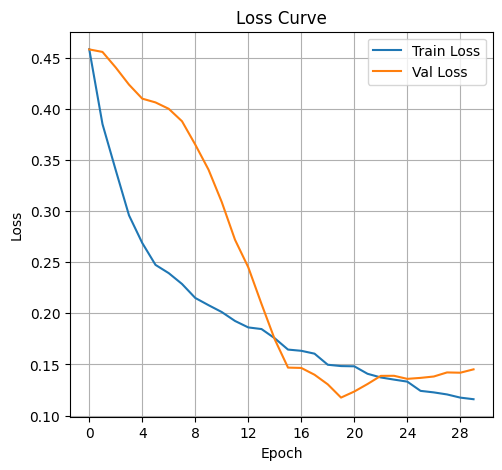

In [ ]:
from matplotlib.ticker import MaxNLocator

plt.figure(figsize=(12,5))

# LOSS
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))



In [ ]:

# PROTOTYPE NORMAL (TRAIN)

emb_normal_train = encoder.predict(Xn_tr, verbose=0)
proto_normal = emb_normal_train.mean(axis=0, keepdims=True)


# DISTANCES VALIDATION

emb_val_normal = encoder.predict(Xn_val, verbose=0)
dist_val_normal = np.linalg.norm(
    emb_val_normal - proto_normal,
    axis=1
)

X_val_full = np.vstack([Xn_val, Xa_val])
y_val_full = np.array([0]*len(Xn_val) + [1]*len(Xa_val))

emb_val_full = encoder.predict(X_val_full, verbose=0)
dist_val_full = np.linalg.norm(
    emb_val_full - proto_normal,
    axis=1
)

In [ ]:
alphas = np.linspace(0.1, 4, 50)

mu = dist_val_normal.mean()
sigma = dist_val_normal.std()

best_alpha = 0
best_f1 = -1

for a in alphas:
    thr = mu + a * sigma
    y_val_pred = (dist_val_full > thr).astype(int)

    f1 = f1_score(y_val_full, y_val_pred)

    if f1 > best_f1:
        best_f1 = f1
        best_alpha = a

threshold = mu + best_alpha * sigma

print("Selected alpha (validation):", best_alpha)
print("Validation F1:", best_f1)
print("Final threshold:", threshold)

Selected alpha (validation): 1.453061224489796
Validation F1: 0.9230769230769231
Final threshold: 0.457541800335962


In [ ]:
X_test = np.vstack([Xn_te, Xa_te])
y_test = np.array([0]*len(Xn_te) + [1]*len(Xa_te))

emb_test = encoder.predict(X_test, verbose=0)
dist_test = np.linalg.norm(
    emb_test - proto_normal,
    axis=1
)

y_test_pred = (dist_test > threshold).astype(int)

Accuracy : 0.7583892617449665
Precision: 0.7954545454545454
Recall   : 0.5645161290322581
F1       : 0.660377358490566
              precision    recall  f1-score   support

      Normal       0.74      0.90      0.81        87
     Anomaly       0.80      0.56      0.66        62

    accuracy                           0.76       149
   macro avg       0.77      0.73      0.74       149
weighted avg       0.76      0.76      0.75       149



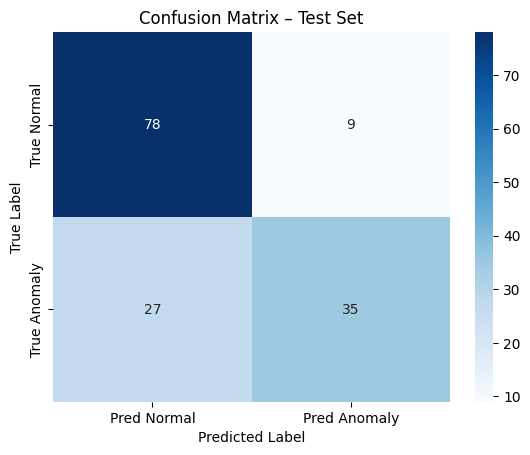

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall   :", recall_score(y_test, y_test_pred))
print("F1       :", f1_score(y_test, y_test_pred))

print(classification_report(
    y_test, y_test_pred,
    target_names=["Normal", "Anomaly"]
))

cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Normal", "Pred Anomaly"],
    yticklabels=["True Normal", "True Anomaly"]
)

plt.title("Confusion Matrix – Test Set")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

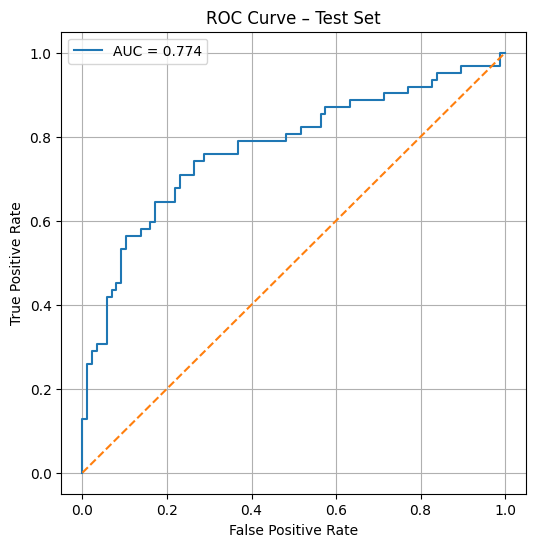

AUC: 0.7740081572117167


In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, dist_test)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")  # ligne aléatoire

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Test Set")
plt.legend()
plt.grid(True)
plt.show()

print("AUC:", roc_auc)
